# 직접 해 보기 2 — 파이썬 코드로 따라 해 보기

AI가 내놓은 결과만 보고 그것이 어떻게 나왔는지 모르면, 그 결과를 믿을 근거도 없다. AI도 실수를 하므로 결과는 점검해야 하고, 점검하려면 결과를 만든 파이썬 코드를 읽을 줄 알아야 한다.

이 노트북은 이 장에서 다룬 계산과 그림, 시뮬레이션을 파이썬으로 직접 해 본다. 보고서의 수치를 다시 만들어 보고, 보고서에는 자세히 나오지 않은 데이터 수집과 로그-로그 회귀도 함께 다룬다. 코드는 될 수 있는 한 단순하게 썼다.

1. 데이터 수집 — 실거래가 CSV를 받아 읽는다
2. 데이터 정리 — 노원구 매매만 남긴다
3. 단순회귀분석 — 가격을 면적에 회귀한다
4. 산점도와 회귀직선 — 보고서의 그림을 그린다
5. 시뮬레이션 ① 직선들의 시합 — 최소제곱이 고른 기울기
6. 시뮬레이션 ② 기울기의 흔들림 — 표본을 바꿔 가며 다시 추정한다
7. 시뮬레이션 ③ 무관한 세상 — 가격표를 섞어 본다
8. $R^2$ 직접 계산 — 평균으로 추측할 때와 직선으로 추측할 때
9. 로그 변환과 로그-로그 회귀 — 탄력성을 추정한다
10. 잔차 산점도 비교 — 로그가 깔때기를 고쳤는지 본다

## 준비 — 패키지와 글꼴

`import`로 쓸 패키지를 불러온다. `as` 뒤의 이름은 줄임말이고, 이후 코드에서는 `np`, `pd`처럼 줄임말로 부른다. 네 패키지는 Anaconda와 Colab에 모두 들어 있다.

matplotlib는 기본 글꼴에 한글이 없어서 그림의 한글이 네모로 깨진다. 그래서 한글 글꼴을 지정한다. 윈도우는 맑은 고딕(`Malgun Gothic`), 맥은 애플고딕(`AppleGothic`)을 쓴다. Colab에는 한글 글꼴이 없으므로 새 셀에서 `!apt-get -qq install fonts-nanum`을 실행하고, 런타임을 다시 시작한 뒤 `NanumGothic`을 지정한다.

In [1]:
import numpy as np                       # 수치 계산
import pandas as pd                      # 표(데이터프레임) 다루기
import statsmodels.formula.api as smf    # 회귀분석
import matplotlib.pyplot as plt          # 그림

# 그림의 한글 글꼴
# 맥은 'AppleGothic', Colab은 'NanumGothic'(설치 필요)
plt.rcParams['font.family'] = 'Malgun Gothic'   # 윈도우
plt.rcParams['axes.unicode_minus'] = False      # 음수 부호(-) 깨짐 방지

## 1. 데이터 수집

**국토교통부 실거래가 공개시스템에서 CSV 받기** — https://rt.molit.go.kr

1. 위쪽 메뉴의 **자료제공 → 조건별 자료제공**으로 들어간다.
2. 부동산 종류는 **아파트**, 거래 유형은 **매매**를 고른다.
3. **계약일자**로 기간을 정한다. 이 장은 1년치를 썼다.
4. 지역을 고른다. 시도만 고르면(예: 서울특별시) 그 안의 모든 구가 들어 있고, 시군구까지 고르면 그 구만 들어 있다. 어느 쪽이든 아래 코드가 구 이름으로 다시 거르므로 그대로 쓸 수 있다.
5. **CSV 다운** 버튼을 누른다. EXCEL이 아니라 CSV로 받아야 아래 코드가 그대로 읽는다.

받은 파일은 엑셀로 열었다가 저장하지 말고 그대로 둔다. 저장하는 순간 형식이 바뀔 수 있다. 공개시스템의 자료는 신고에 따라 계속 바뀌므로, 같은 기간을 받아도 이 장의 건수와 조금 다를 수 있다.

**노트북에서 불러오기**

- 내 컴퓨터의 주피터: CSV를 이 노트북 파일과 같은 폴더에 두고, 아래 코드의 `CSV =` 줄에 파일 이름을 그대로 적는다. 다른 폴더에 두었다면 전체 경로를 적는다. 예: `CSV = r'C:\Users\나\Downloads\아파트(매매)_실거래가.csv'`(윈도우 경로는 따옴표 앞에 `r`을 붙인다).
- Colab: 왼쪽의 폴더 아이콘을 누르고 업로드 버튼으로 CSV를 올린다. 올린 파일은 `/content/` 아래에 놓이므로 `CSV = '/content/파일이름.csv'`로 적는다. 업로드한 파일은 런타임이 끝나면 지워진다.

**읽기**

받은 CSV에는 세 가지 특징이 있고, `pd.read_csv`의 옵션 셋이 하나씩 맡는다.

- 한글 인코딩이 cp949다 → `encoding='cp949'`
- 표 위에 안내문 15줄이 붙어 있다 → `skiprows=15`
- 거래금액에 천 단위 쉼표가 있다(51,500) → `thousands=','`

읽은 뒤 변수 이름이 이상하게 나오면 안내문 줄 수가 다른 것이다. CSV를 메모장으로 열어 `"NO"`로 시작하는 머리글 줄 앞에 몇 줄이 있는지 세어 `skiprows`를 고친다.

In [2]:
CSV = 'seoul-apt-sales-2025-10-2026-10.csv'   # 자기 파일 이름으로 바꾼다

df = pd.read_csv(CSV,
                 encoding='cp949',   # 한글 인코딩
                 skiprows=15,        # 표 위 안내문 15줄 건너뜀
                 thousands=',')      # 51,500 → 51500
print('서울 전체', len(df), '건')
df.head(3)                           # 앞 3줄 확인

서울 전체 68767 건


,NO,시군구,번지,본번,부번,단지명,전용면적(㎡),계약년월,계약일,거래금액(만원),동,층,매수자,매도자,건축년도,도로명,해제사유발생일,거래유형,중개사소재지,등기일자
0,1,서울특별시 도봉구 방학동,732,732,0,신동아아파트4,84.9000,202610,6,51500,-,4,개인,개인,1995,방학로 200,-,중개거래,서울 도봉구,-
1,2,서울특별시 금천구 독산동,1155,1155,0,금천롯데캐슬골드파크3차,59.9662,202610,6,110000,-,8,개인,개인,2018,시흥대로 291,-,중개거래,서울 금천구,-
2,3,서울특별시 중랑구 면목동,193-1,193,1,면목한신,35.3000,202610,5,36800,-,8,개인,개인,1988,중랑천로 20,-,중개거래,서울 중랑구,-


## 2. 데이터 정리

보고서의 분석 대상은 "노원구 아파트 매매, 해제거래 제외"다. 세 단계로 좁힌다.

1. 계약이 해제된 거래를 뺀다. 해제되지 않은 거래는 `해제사유발생일` 변수에 `-`가 적혀 있다.
2. `시군구` 변수("서울특별시 노원구 상계동" 꼴)에 "노원구"가 들어 있는 거래만 남긴다.
3. 거래금액을 만원에서 억원으로 바꾸고, 짧은 이름의 새 변수(`가격`, `면적`)로 둔다. 괄호가 든 변수 이름은 다음 절의 회귀식에 그대로 쓸 수 없기 때문이다.

`df[조건]`은 조건이 참인 행만 남긴다. 판다스에서 표를 거르는 가장 기본적인 방법이다. 끝의 `.copy()`는 걸러 낸 표를 별도의 표로 만든다. 이것이 없으면 새 변수를 만들 때 경고가 나올 수 있다.

In [3]:
df = df[df['해제사유발생일'] == '-']                  # 1) 해제거래 제외
d = df[df['시군구'].str.contains('노원구')].copy()    # 2) 노원구만

d['가격'] = d['거래금액(만원)'] / 10000              # 3) 만원 → 억원
d['면적'] = d['전용면적(㎡)']

print('노원구 매매', len(d), '건')
print('중위 가격', round(d['가격'].median(), 2), '억원')
print('평균 가격', round(d['가격'].mean(), 2), '억원')

노원구 매매 7366 건
중위 가격 6.1 억원
평균 가격 6.6 억원


## 3. 단순회귀분석

`smf.ols('가격 ~ 면적', data=d)`가 회귀식을 정한다. `~` 왼쪽이 설명되는 변수(가격), 오른쪽이 설명하는 변수(면적)다. 절편은 자동으로 들어간다. `.fit()`이 최소제곱으로 절편과 기울기를 계산한다.

`summary()`는 결과를 표로 보여 준다. 보고서의 회귀 결과 표와는 이렇게 대응한다.

| summary | 보고서 |
|---|---|
| `coef` | 추정값 |
| `std err` | 표준오차 |
| `t` | $t$값 |
| P>\|t\| | $p$값 |
| `[0.025  0.975]` | 95% 신뢰구간 |
| `R-squared` | $R^2$ |
| `No. Observations` | $n$ |

P>\|t\|가 `0.000`으로 나오는 것은 $p$값이 0이라는 뜻이 아니다. 소수 셋째 자리까지 0일 만큼 작다는 뜻이고, 보고서는 이것을 "< 0.001"로 적는다.

summary는 소수 셋째 자리까지만 보여 준다. 그래서 기울기의 표준오차 0.0009가 `0.001`로 보인다. 정확한 값은 다음 셀에서 `m.bse`로 꺼내 본다.

In [4]:
m = smf.ols('가격 ~ 면적', data=d).fit()   # 가격 = a + b × 면적
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:                     가격   R-squared:                       0.542
Model:                            OLS   Adj. R-squared:                  0.542
Method:                 Least Squares   F-statistic:                     8731.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        01:39:33   Log-Likelihood:                -13986.
No. Observations:                7366   AIC:                         2.798e+04
Df Residuals:                    7364   BIC:                         2.799e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.4783      0.058     25.521      0.0

summary에 없는 숫자는 결과에서 꺼내 계산한다. `m.params`에 절편과 기울기가 들어 있다.

- 기울기 0.0818억원은 만원 단위로 바꾸면 818만원이다.
- 잔차 표준오차는 잔차제곱의 평균(`m.mse_resid`)에 제곱근을 씌운 값이다. 같은 면적이라도 실제 가격이 회귀직선에서 보통 얼마나 떨어져 있는지를 원래 단위(억원)로 보여 준다.
- 표준오차는 `m.bse`에 들어 있다. summary보다 자릿수를 늘려 찍으면 보고서의 0.0009가 보인다.
- 회귀식 기준 가격은 회귀식에 면적을 넣어 계산한다.

In [5]:
a = m.params['Intercept']   # 절편
b = m.params['면적']        # 기울기

print('기울기', round(b, 4), '억원 =', round(b * 10000), '만원')
print('기울기의 표준오차', round(m.bse['면적'], 4))
print('잔차 표준오차', round(np.sqrt(m.mse_resid), 2), '억원')

# 회귀식 기준 가격
print('전용 59㎡', round(a + b * 59, 1), '억원')
print('전용 84㎡', round(a + b * 84, 1), '억원')

기울기 0.0818 억원 = 818 만원
기울기의 표준오차 0.0009
잔차 표준오차 1.62 억원
전용 59㎡ 6.3 억원
전용 84㎡ 8.3 억원


## 4. 산점도와 회귀직선

`plt.scatter`가 점을, `plt.plot`이 선을 그린다. 점 하나가 거래 한 건이다. 점이 7천 개가 넘어 겹침이 심하므로 점을 작게(`s=5`), 투명하게(`alpha=0.3`) 찍는다.

회귀직선은 면적의 최솟값부터 최댓값까지 100개 점을 만들고(`np.linspace`), 각 점에서 회귀식의 값을 계산해 이어 그린다. 색은 책의 그림과 같게 점은 파랑, 회귀직선은 주황으로 했다.

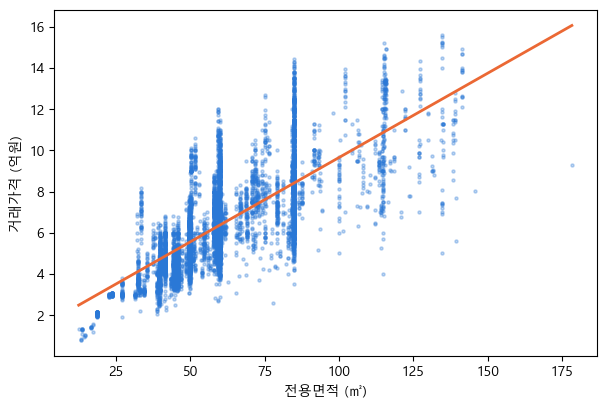

In [6]:
plt.figure(figsize=(7, 4.5))

# 점: 거래 한 건씩
plt.scatter(d['면적'], d['가격'], s=5, alpha=0.3, color='#2a78d6')

# 회귀직선: x 100개에서 a + b × x
xs = np.linspace(d['면적'].min(), d['면적'].max(), 100)
plt.plot(xs, a + b * xs, color='#eb6834', linewidth=2)

plt.xlabel('전용면적 (㎡)')
plt.ylabel('거래가격 (억원)')
plt.show()

## 5. 시뮬레이션 ① 직선들의 시합

2절에서 본 시합을 숫자로 재현한다. 직선의 벌점은 평균 잔차제곱이다. 잔차(실제 가격 − 직선의 예측)를 제곱해 평균한 값이다.

후보 직선은 모두 평균점(평균 면적, 평균 가격)을 지나게 하고 기울기만 바꾼다. 너무 완만한 0.04, 최소제곱이 고른 기울기, 너무 가파른 0.13을 시합시킨다. 최소제곱이 고른 기울기의 벌점이 가장 낮게 나와야 한다.

`def`는 함수를 만든다. 기울기를 넣으면 벌점을 돌려주는 함수를 만들어 세 번 부른다.

In [7]:
x = d['면적']
y = d['가격']

def penalty(slope):
    # 평균점을 지나고 기울기가 slope인 직선의 평균 잔차제곱
    pred = y.mean() + slope * (x - x.mean())
    return np.mean((y - pred) ** 2)

for slope in [0.04, b, 0.13]:
    print('기울기', round(slope, 4), '→ 벌점', round(penalty(slope), 2))

기울기 0.04 → 벌점 3.42
기울기 0.0818 → 벌점 2.61
기울기 0.13 → 벌점 3.69


## 6. 시뮬레이션 ② 기울기의 흔들림

3절의 가상 실험이다. 노원구 7,366건을 잠시 "모집단"으로 두고, 그 가운데 200건을 무작위로 뽑아 기울기를 추정한다. 이것을 2,000번 되풀이하면 기울기가 표본에 따라 얼마나 흔들리는지 보인다. 흔들림의 크기(기울기들의 표준편차)가 표준오차의 뜻이다.

- `np.random.default_rng(시드)`는 난수 생성기다. 시드를 정해 두면 몇 번을 실행해도 같은 결과가 나온다.
- `rng.integers(0, n, 200)`은 0부터 n−1 사이의 번호 200개를 뽑는다. 같은 번호가 다시 뽑힐 수 있다(복원추출).
- `np.polyfit(x, y, 1)`은 직선(1차식)을 최소제곱으로 맞추고 `[기울기, 절편]`을 돌려준다. 회귀식 표가 필요 없을 때 쓰는 간단한 방법이다. 2,000번 반복하므로 빠른 쪽을 쓴다.

뽑는 건수를 200 → 1,000 → 7,366으로 늘리면 흔들림이 줄어든다. 7,366건에서의 흔들림은 보고서의 표준오차 0.0009와 거의 같은 크기다. 보고서의 표준오차는 이런 반복 없이 공식으로 한 번에 계산한 값이지만, 그 공식이 재는 것이 바로 이 흔들림이다.

200건: 평균 0.082  흔들림(표준편차) 0.0066


1000 건: 흔들림 0.0028


7366 건: 흔들림 0.0011


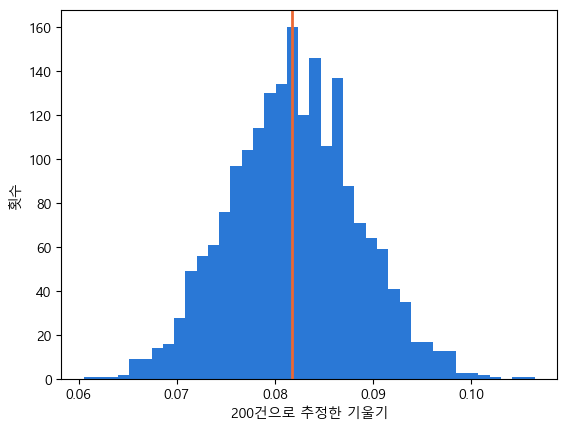

In [8]:
rng = np.random.default_rng(20261007)   # 시드 고정
xv, yv = x.to_numpy(), y.to_numpy()     # 빠른 계산용 배열
n = len(xv)

def slopes(size, reps=2000):
    # size건씩 뽑아 기울기를 reps번 추정
    out = []
    for i in range(reps):
        idx = rng.integers(0, n, size)                    # 번호 size개 (복원추출)
        out.append(np.polyfit(xv[idx], yv[idx], 1)[0])    # [0] = 기울기
    return np.array(out)

s200 = slopes(200)
print('200건: 평균', round(s200.mean(), 4), ' 흔들림(표준편차)', round(s200.std(), 4))
for size in [1000, n]:
    print(size, '건: 흔들림', round(slopes(size).std(), 4))

plt.hist(s200, bins=40, color='#2a78d6')
plt.axvline(b, color='#eb6834', linewidth=2)   # 7,366건 전체의 기울기
plt.xlabel('200건으로 추정한 기울기')
plt.ylabel('횟수')
plt.show()

## 7. 시뮬레이션 ③ 무관한 세상

3절의 두 번째 실험이다. 7,366건의 가격표를 떼어 무작위로 뒤섞어 다시 붙이면, 면적과 가격의 관계가 완전히 끊어진 세상이 된다. `rng.permutation(yv)`가 가격의 순서를 무작위로 섞는다.

이런 세상에서도 우연 때문에 기울기가 정확히 0은 아니다. 2,000번 섞어 보면 우연이 만드는 기울기가 어느 정도인지 알 수 있다. 실제 기울기 0.0818이 그 범위 안에 들어오는지 본다. 아득히 바깥이면 "면적과 가격이 무관하다"는 가정으로는 실제 기울기를 설명할 수 없다. 이것이 $t$값과 $p$값의 직관이다.

무관한 세상의 기울기: 가장 큰 값 0.0045
실제 기울기 0.0818


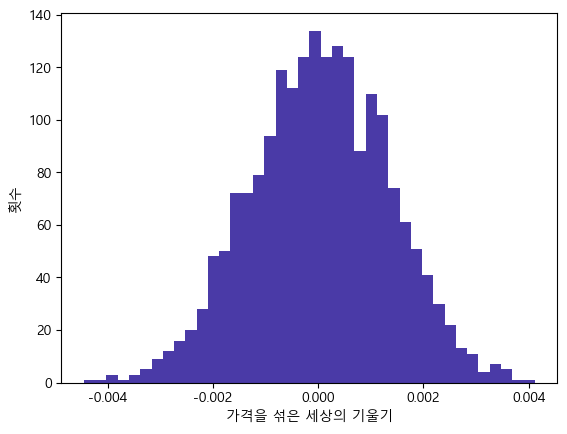

In [9]:
null = []
for i in range(2000):
    y_mixed = rng.permutation(yv)                   # 가격표 섞기
    null.append(np.polyfit(xv, y_mixed, 1)[0])
null = np.array(null)

print('무관한 세상의 기울기: 가장 큰 값', round(np.abs(null).max(), 4))
print('실제 기울기', round(b, 4))

plt.hist(null, bins=40, color='#4a3aa7')
plt.xlabel('가격을 섞은 세상의 기울기')
plt.ylabel('횟수')
plt.show()

## 8. $R^2$ 직접 계산

4절의 계산이다. 면적을 모를 때 가격을 맞히는 최선의 추측은 평균이다. 이때의 벌점(평균 잔차제곱)이 원래 흩어짐이다. 면적을 알고 회귀직선으로 추측하면 벌점이 줄어든다. $R^2$는 원래 흩어짐 가운데 회귀직선이 줄여 준 몫이다.

$R^2$ = (원래 흩어짐 − 남은 흩어짐) ÷ 원래 흩어짐

`m.resid`에 회귀직선의 잔차가 들어 있다. 계산한 값이 summary의 `R-squared`와 같은지 확인한다.

In [10]:
before = np.mean((y - y.mean()) ** 2)   # 평균으로 추측: 원래 흩어짐
after = np.mean(m.resid ** 2)           # 직선으로 추측: 남은 흩어짐

print('원래 흩어짐', round(before, 1))
print('남은 흩어짐', round(after, 1))
print('R² =', round((before - after) / before, 3))
print('summary의 R²:', round(m.rsquared, 3))

원래 흩어짐 5.7
남은 흩어짐 2.6
R² = 0.542
summary의 R²: 0.542


## 9. 로그 변환과 로그-로그 회귀

가격과 면적에 모두 로그를 취해 회귀하면 기울기가 탄력성이 된다. 면적이 1% 넓을 때 가격이 몇 % 높은지를 뜻한다. `np.log`는 자연로그다.

로그를 취한 값을 새 변수로 만들어 두면 회귀식을 앞과 똑같은 꼴로 쓸 수 있다.

탄력성 추정값 0.84는 면적이 1% 넓으면 가격이 평균 약 0.84% 높다는 뜻이다. 1보다 작으므로 큰 평수일수록 ㎡당 단가는 낮아진다.

summary의 `R-squared`도 0.54에서 0.61로 높아진다. 다만 두 $R^2$는 설명하는 대상(가격, 로그가격)이 서로 달라서, 크기를 그대로 비교하는 것은 엄밀하지 않다.

In [11]:
d['로그가격'] = np.log(d['가격'])   # 자연로그
d['로그면적'] = np.log(d['면적'])

mlog = smf.ols('로그가격 ~ 로그면적', data=d).fit()
print(mlog.summary())

                            OLS Regression Results                            
Dep. Variable:                   로그가격   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                 1.134e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        01:39:35   Log-Likelihood:                 319.20
No. Observations:                7366   AIC:                            -634.4
Df Residuals:                    7364   BIC:                            -620.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.5880      0.032    -49.433      0.0

In [12]:
e = mlog.params['로그면적']   # 기울기 = 탄력성
ci = mlog.conf_int().loc['로그면적']

print('탄력성', round(e, 2))
print('95% 신뢰구간', round(ci[0], 2), '~', round(ci[1], 2))

탄력성 0.84
95% 신뢰구간 0.82 ~ 0.85


## 10. 잔차 산점도 비교

4절에서 원래 단위 모형의 잔차는 큰 평수로 갈수록 넓게 흩어지는 깔때기 모양이었다. 5절은 로그를 처방으로 제시했다. 두 모형의 잔차를 나란히 그려 처방이 통했는지 본다.

- 원래 단위 모형의 잔차는 억원 단위다.
- 로그-로그 모형의 잔차에 100을 곱하면 대략 % 단위의 빗나감으로 읽을 수 있다.

`plt.subplots(1, 2)`는 그림 칸 두 개를 가로로 만든다. `ax[0]`이 왼쪽, `ax[1]`이 오른쪽 칸이다. `axhline(0)`은 잔차 0인 수평선, 곧 회귀직선의 자리다.

그림만으로 판단하지 않고 숫자로도 확인한다. 소형(40㎡ 미만)과 대형(100㎡ 초과)의 잔차 표준편차를 비교한다. 원래 단위는 ±1.1억에서 ±2.4억으로 두 배 넘게 벌어지고, 로그-로그는 ±25%와 ±24%로 거의 같아야 한다.

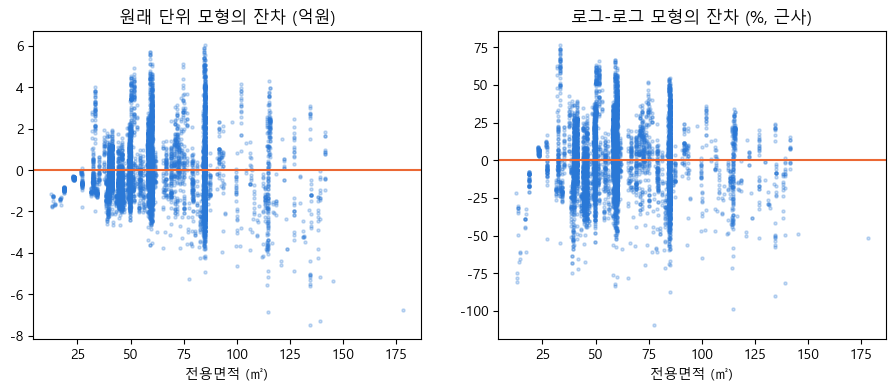

In [13]:
r = m.resid               # 원래 단위 잔차 (억원)
rlog = mlog.resid * 100   # 로그 잔차 × 100 ≈ % 빗나감

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(x, r, s=5, alpha=0.25, color='#2a78d6')
ax[0].axhline(0, color='#eb6834')          # 회귀직선 자리
ax[0].set_title('원래 단위 모형의 잔차 (억원)')
ax[0].set_xlabel('전용면적 (㎡)')

ax[1].scatter(x, rlog, s=5, alpha=0.25, color='#2a78d6')
ax[1].axhline(0, color='#eb6834')
ax[1].set_title('로그-로그 모형의 잔차 (%, 근사)')
ax[1].set_xlabel('전용면적 (㎡)')

plt.show()

In [14]:
small = x < 40    # 소형
large = x > 100   # 대형

print('원래 단위  소형 ±', round(r[small].std(), 1), '억')
print('원래 단위  대형 ±', round(r[large].std(), 1), '억')
print('로그-로그  소형 ±', round(rlog[small].std()), '%')
print('로그-로그  대형 ±', round(rlog[large].std()), '%')

원래 단위  소형 ± 1.1 억
원래 단위  대형 ± 2.4 억
로그-로그  소형 ± 25 %
로그-로그  대형 ± 24 %


## 정리

이 노트북의 코드는 이 장에서 본 숫자와 그림을 직접 만들어 냈다. 보고서의 회귀 결과는 `smf.ols(...).fit()`과 `summary()` 두 줄에서 나오고, 책의 시뮬레이션은 뽑기·섞기·반복을 몇 줄로 쓴 것이다.

다른 구를 분석하려면 2절의 `'노원구'`를 원하는 구 이름(예: `'강서구'`)으로 바꾸고 처음부터 다시 실행한다. AI가 만든 보고서를 받았다면, 이 코드로 같은 숫자가 나오는지 확인해 보는 것이 가장 확실한 점검이다.